# BUCKL readiness model

**Question:** before a drive, will this driver have a fatigue episode on the trip?
**Inputs:** what the app collects in the pre-drive check: 4 questions, 30-second tap test, 15-second face reading, time of day, past trips.
**Output:** a probability, turned into *Safe to drive / Caution / High risk*.

**Data:** no labelled real drives exist yet, so we simulate 30,000 drivers from published sleep research
(two-process model of sleepiness, body-clock dips, reaction-time slowing and lapses after short sleep,
people under-rating their own sleepiness, PERCLOS). See `README.md` and `train_readiness.py` for every assumption.
The app stores each real check, so the same script can retrain on real data later.

In [1]:
import json, subprocess, sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
subprocess.run([sys.executable, 'train_readiness.py'], check=True, capture_output=True)
metrics = json.loads(Path('out/metrics.json').read_text())

## The simulated drivers (first rows)

In [2]:
df = pd.read_csv('out/simulated_drivers.csv')
print(f"{len(df):,} drivers, {df.episode.mean():.0%} had a fatigue episode")
df.head()

30,000 drivers, 25% had a fatigue episode


,slept,awake,hour_sin,hour_cos,night,alert_self,trip_hours,reaction_slowing_ms,misses,face_perclos,face_mean_blink_ms,face_yawns,history,episode
0,8.0,18.0,0.707107,0.707107,1.0,3.0,0.75,104.287209,2.0,0.180149,290.935892,2.0,0.121732,1
1,5.5,4.0,-0.866025,-0.500000,0.0,0.0,0.40,99.457753,0.0,0.188831,201.395080,1.0,0.018187,0
2,6.5,4.0,0.500000,-0.866025,0.0,0.0,0.40,21.988412,0.0,0.071987,240.169721,0.0,0.007723,1
3,6.5,14.0,-0.866025,0.500000,0.0,0.0,0.75,54.746675,0.0,0.140884,204.657204,1.0,0.000000,0
4,8.0,18.0,0.500000,0.866025,1.0,3.0,3.00,99.455856,1.0,0.148902,341.320216,0.0,0.181589,1


## Model: logistic regression
Chosen because every weight can be read and explained, and it runs on the phone or server with no ML library. A gradient-boosting model was trained as a check and scored the same AUC, so the simpler model loses nothing.

In [3]:
pd.DataFrame({'AUC (test set, 9,000 drivers)': metrics['auc']})

,"AUC (test set, 9,000 drivers)"
self_report_only,0.6626
old_hand_set_rule,0.7756
buckl_model_logistic,0.8418
gradient_boosting_check,0.8423


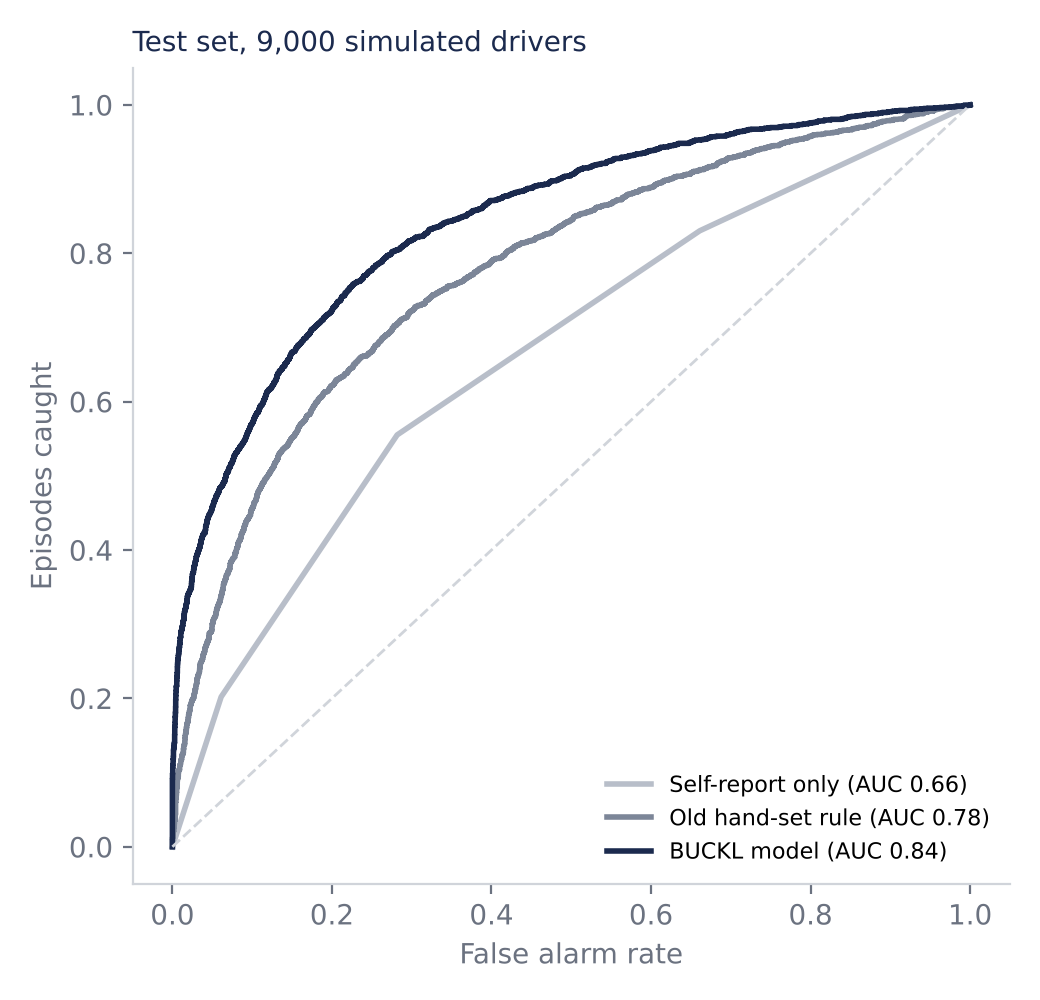

In [4]:
display(Image('out/roc.png', width=420))

## Proof it helps a decision
Give the same number of warnings as simply asking *"how alert do you feel?"*. Which approach warns more of the drivers who really go on to have a fatigue episode?

In [5]:
pd.Series(metrics['same_number_of_warnings'])

warning_rate                   0.3503
episodes_warned_self_report    0.5552
episodes_warned_old_rule       0.6633
episodes_warned_buckl_model    0.7470
dtype: float64

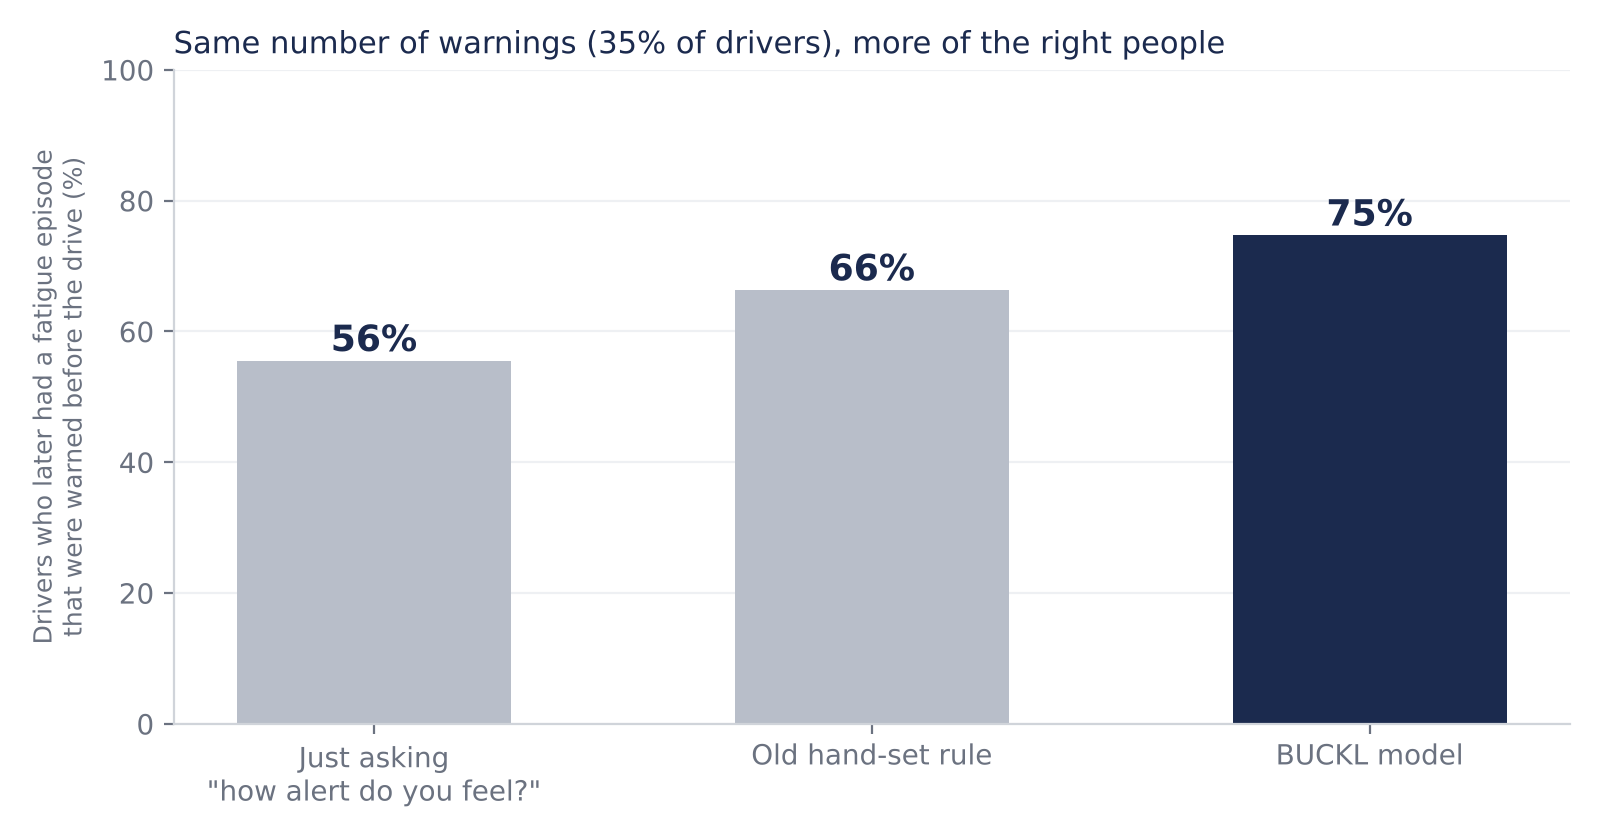

In [6]:
display(Image('out/warned_comparison.png', width=640))

## What each result band means

In [7]:
b = metrics['bands']
pd.DataFrame({'share of drivers': b['share_of_drivers'], 'had an episode': b['episode_rate_in_band']}).style.format('{:.0%}')

,share of drivers,had an episode
safe,65%,10%
caution,25%,41%
high,10%,85%


## What the model learned

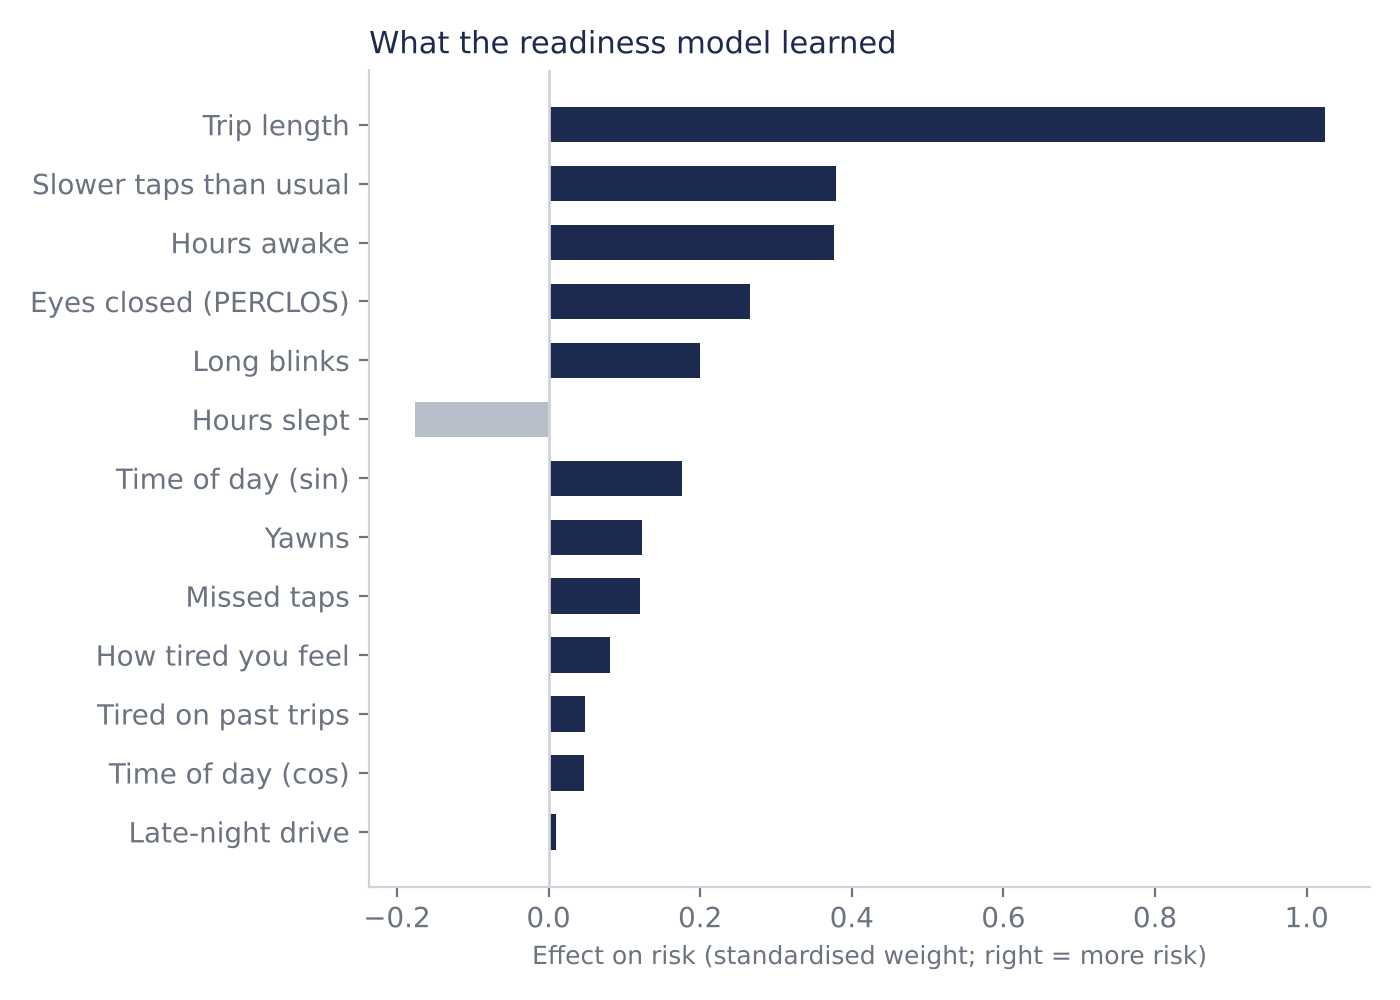

In [8]:
display(Image('out/what_it_learned.png', width=560))

## Limits (say these out loud)
- Trained on **simulated** drivers, so the numbers show the method works, not real-world accuracy.
- Next step: retrain on real pre-drive checks + in-drive fatigue events the app already records.
- A safety indication, not a medical diagnosis.